# Which index should it pay on?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/marc272/crc-docs/blob/parametric/notebooks/which_index_should_it_pay_on.ipynb)

A parametric cover pays on a measured number, the **index**, not on the loss. The
[primer](parametric_insurance_primer.ipynb) wrote one for an imaginary Toronto
brewery, and [how the module works](parametric_insurance_module.ipynb) showed the
parametric module of [crc-sdk](https://github.com/RiskThinking/crc-sdk) behind it.
Here, one question: **which index should it pay on?**

Basis risk comes from the index: it should pass its trigger in the years the
brewery loses. A curve says how often an index passes a level, not in which years,
so comparing indices takes real years: ERA5's, 1959 to 2021.

**The one thing to take away: an index is a choice you can test on real years,
against a loss you state. On 63 years the answer comes with wide intervals.**

On Colab choose **Runtime → Run all**; no account needed. The first run installs
crc-sdk, downloads one small CRC Open file and reduces 63 years of ERA5's hourly
rain twice, which took about an hour and a half on our test machine; later runs read the cache.

## Setup

In [1]:
#@title Install packages (Colab)
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None

# crc_sdk.parametric is not in a crc-sdk release yet: install it from its development branch.
# zarr and netcdf read ERA5's public copy.
CRC_SDK = "crc-sdk[geometry,parametric,zarr,netcdf] @ git+https://github.com/marc272/crc-sdk@parametric"


def has_parametric():
    spec = importlib.util.find_spec("crc_sdk")
    return (spec is not None and spec.origin is not None and (Path(spec.origin).parent / "parametric").is_dir()
            and importlib.util.find_spec("zarr") is not None)


def pip_install(*arguments):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--disable-pip-version-check", *arguments])


if IN_COLAB or not has_parametric():
    if importlib.util.find_spec("pip") is None:  # a bare virtual environment
        subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"], stdout=subprocess.DEVNULL)
    pip_install(CRC_SDK, "plotly>=6,<7", "pandas>=2.2")
    if not has_parametric():  # a crc-sdk release of the same version number was already installed
        pip_install("--force-reinstall", "--no-deps", CRC_SDK)
    importlib.invalidate_caches()

# Small, quick runs for continuous integration; the same code runs either way.
CI = os.environ.get("CRC_DOCS_CI") == "1"

In [2]:
import warnings

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow as pa
from IPython.display import display
from plotly.subplots import make_subplots

import highspy
from crc_sdk.impacts import ImpactCalibration, ImpactExpression
from crc_sdk.parametric import (
    AnnualSeries, Budget, CompositeIndex, Cover, ExpectedUncovered, Free, HazardNoise, IndexDefinition, Limit,
    LinearPayout, LossModel, MetricOptions, StepGrid, StepPayout, bootstrap_intervals, compare_pooled, design, evaluate,
    sample_annual, sample_annual_hazards, sample_curve, setup_text, year_block_kfold,
)
from crc_sdk.workflows import BlockExtremaPolicy, HazardDataset
from crc_sdk.workflows.distributions import ReturnPeriodExtrapolationWarning

# About 1 simulated year in 1,000 falls outside the return periods the curve was fitted on
# (1.001 to 1,000 years), where it is extrapolated. The setup text counts them; we silence the warning.
warnings.simplefilter("ignore", ReturnPeriodExtrapolationWarning)

# The solver, HiGHS, prints its banner once, when first started: here, rather than among the results.
highspy.Highs()

# Interactive charts when you run it; saved images so GitHub can show them too.
STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000

# The primer's folder: its CRC Open file is downloaded once for the notebooks of the set.
DATA = Path("data") / "parametric_primer"
DATA.mkdir(parents=True, exist_ok=True)

# As in the primer, orange is always the loss and blue the payout.
INK, BLUE, ORANGE, MUTED, LIGHT = "#52514e", "#2a78d6", "#eb6834", "#8a8880", "#f0efec"
FONT = dict(family="Inter, Helvetica, Arial, sans-serif", size=14)


def layout(fig, title, setup, height=500, bottom=70, top=120, left=75, **kwargs):
    """Style a chart and state its setup under the title, so the numbers never lose it."""
    fig.update_layout(title=dict(text=title, x=0.01, y=0.97, yanchor="top",
                                 subtitle=dict(text=setup, font=dict(size=11, color=MUTED))),
                      font=FONT, height=height, margin=dict(l=left, r=30, t=top, b=bottom), hoverlabel=dict(font_size=13), **kwargs)
    return fig


def cad(value):
    return f"CAD {value:,.0f}"

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


**The example.** Wet Basement Brewing is the primer's imaginary brewery: a stated
value of CAD 5 million, with a hypothetical damage curve from 40 mm of rain in a day.
Its first cover pays nothing below 45 mm on the year's wettest day and CAD 500,000
from 75 mm. The primer set those terms on simulated years from CRC Open's curve for
the site's hexagon (SSP5-8.5, 2030, no historical baseline); we draw them again so
the module can check that the years below are new to the cover.

In [3]:
RELEASE, PATHWAY, HORIZON = "ssp585-global-2026-10-20-v1", "ssp585", 2030
ASSET = {"asset_id": "Wet Basement Brewing", "longitude": -79.38, "latitude": 43.65, "value_cad": 5_000_000.0}

# Downloads and checks the CRC Open file once, then reads the cached copy.
dataset = (
    HazardDataset.crc_open(release=RELEASE)
    .hazards(["rx1day"])
    .horizons([HORIZON])
    .for_area((-79.40, 43.63, -79.36, 43.67))  # (west, south, east, north), enough to find the site's hexagon
    .cache(DATA / "crc-open", mode="reuse")
    .ensure_materialized()
)
metadata = dataset.metadata()
curve_row = (
    dataset.for_assets(pa.Table.from_pylist([ASSET]))
    .select(hazard_names=["rx1day"], horizons=[HORIZON], pathways=[PATHWAY])
    .asset_curves()
    .to_pylist()[0]
)
DAMAGE = ImpactExpression.tabulated(
    [(40.0, 0.0), (50.0, 0.02), (60.0, 0.06), (75.0, 0.15), (100.0, 0.30)],
    calibration=ImpactCalibration(exposure_variable="rx1day", exposure_unit="mm/day",
                                  impact_metric="damage_ratio", impact_unit="1"),
    clamp={"minimum": 0.0, "maximum": 1.0},
)
SIGMA = 0.25
loss_model = LossModel(DAMAGE, value=ASSET["value_cad"], value_unit="CAD")
basis_risk = HazardNoise(SIGMA)  # the rain at the brewery: the index's rain times a random factor with mean 1
OPTIONS = MetricOptions(betas=(0.9,), return_periods=(10.0,))

N_YEARS = 2_000 if CI else 20_000
# The primer's design years (its seed 42): the years the first cover's terms were set beside.
design_years = sample_curve(curve_row, metadata=metadata, n_draws=N_YEARS, rng=np.random.default_rng(42),
                            loss_model=loss_model, basis_risk=basis_risk, asset_id=ASSET["asset_id"])
one_day = IndexDefinition("rx1day", "mm/day", aggregation="annual_maximum")
first_cover = Cover(one_day, LinearPayout(45.0, 75.0, 500_000.0), payout_unit="CAD", label="First cover")
print(f"{N_YEARS:,} design years from CRC Open rx1day, release {RELEASE}, pathway {PATHWAY}, horizon {HORIZON} "
      f"(no historical baseline), hexagon {curve_row['cell_index']:x}.")
print(f"Licence: {metadata.source.licence}. Attribution: {metadata.source.attribution}.")

20,000 design years from CRC Open rx1day, release ssp585-global-2026-10-20-v1, pathway ssp585, horizon 2030 (no historical baseline), hexagon 852b9bc7fffffff.
Licence: CC-BY-NC-4.0. Attribution: Riskthinking.AI bias-corrected climate distributions.


## 1. The flood the index missed

What would that cover have paid in real years? CRC Open has no past, so we read
**ERA5**, the reanalysis of [How hard will it rain?](how_hard_will_it_rain.ipynb),
on its free 1.5° grid. The brewery's cell is about 120 km by 170 km, and it smooths
out the storms a street feels.

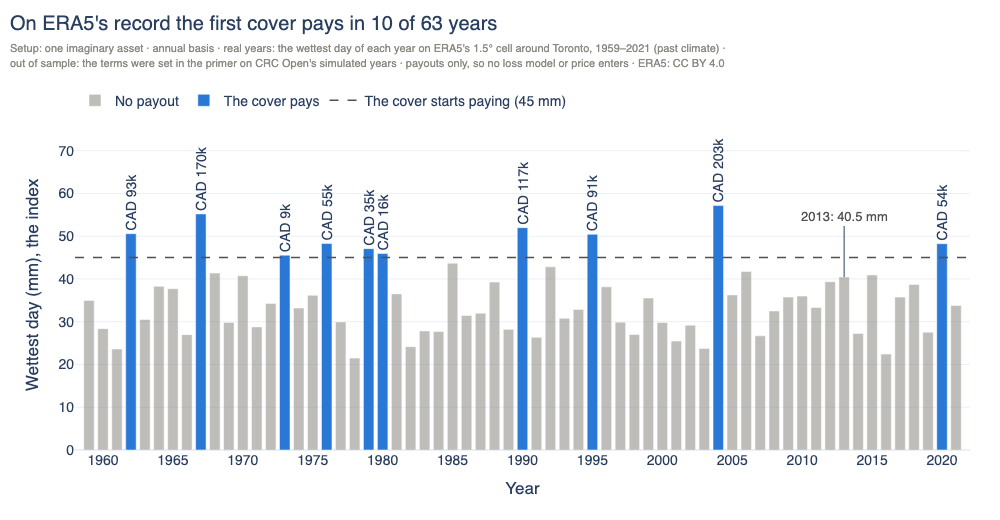

1959–2021: pays in 15.9% of years, CAD 842,428 in total; never the full CAD 500,000, because the cell's wettest day never reaches 75 mm (highest: 57.2 mm, in 2004). Setup:

Level: asset (Wet Basement Brewing). Scenario: baseline. Basis: annual, one draw is one year.
Split: out of sample, fold 0, on a separate sample from another source: evaluated on 63 recorded years (1959 to 2021); designed on 20000 simulated years (draws 0 to 19999); the leakage check passed: the two share no period of one source.
Sample of 63 recorded years (1959 to 2021): per-year values, one row per recorded year. Basis risk: hazard noise, the hazard at the asset being the index times a mean-one lognormal factor with sigma 0.25, one per year and asset, as an assumption the caller states; over the rows as built, with the model over without it (sigma 0, on the same draws), the expected loss is 1.29449 and the mean hazard is 0.991797. Loss: impact expression tabulated (c7eef8f12dda) for hazard values in mm/day times 

In [4]:
ERA5_YEARS = (2014, 2021) if CI else (1959, 2021)
# (west, south, east, north), enough to find the brewery's 1.5° cell.
AREA = (ASSET["longitude"] - 0.1, ASSET["latitude"] - 0.1, ASSET["longitude"] + 0.1, ASSET["latitude"] + 0.1)


def era5_annual(recipe):
    """Each year's extreme on the brewery's ERA5 cell: reduced from hourly rain once, then read from the cache."""
    plan = (
        HazardDataset.era5(recipe, store="wb2-1p5")
        .for_area(AREA)
        .years(*ERA5_YEARS)
        .cache(DATA / "era5", mode="reuse")
        .canonicalize(policy=BlockExtremaPolicy.curated(h3_resolution=5, minimum_years=8 if CI else 20))
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return plan, plan.annual_extremes()


def series(recipe, unit):
    plan, table = era5_annual(recipe)
    return AnnualSeries.nearest_cell(table, longitude=ASSET["longitude"], latitude=ASSET["latitude"], unit=unit,
                                     spacing=(1.5, 1.5), source=plan)


rain = series("rx1day", "mm/day")
years, wettest_day = np.asarray(rain.years, dtype=int), np.asarray(rain.values, dtype=float)
paid = first_cover.payout_values(wettest_day)
paying = paid > 0

fig = go.Figure()
fig.add_trace(go.Bar(x=years[~paying], y=wettest_day[~paying], name="No payout", marker_color=MUTED, opacity=0.55,
                     hovertemplate="%{x}: wettest day %{y:.1f} mm, no payout<extra></extra>"))
fig.add_trace(go.Bar(x=years[paying], y=wettest_day[paying], name="The cover pays", marker_color=BLUE,
                     text=[f"CAD {value / 1000:.0f}k" for value in paid[paying]], textposition="outside", textangle=-90,
                     constraintext="none", cliponaxis=False, customdata=paid[paying],
                     hovertemplate="%{x}: wettest day %{y:.1f} mm, pays CAD %{customdata:,.0f}<extra></extra>"))
fig.add_trace(go.Scatter(x=[years.min() - 1, years.max() + 1], y=[45, 45], mode="lines", name="The cover starts paying (45 mm)",
                         line=dict(color=INK, width=1.5, dash="dash"), hoverinfo="skip"))
if 2013 in years:
    rain_2013 = float(wettest_day[years == 2013][0])
    fig.add_annotation(x=2013, y=rain_2013, text=f"2013: {rain_2013:.1f} mm", showarrow=True, arrowhead=0, ax=0, ay=-60,
                       font=dict(color=INK, size=13))
layout(fig, f"On ERA5's record the first cover pays in {int(paying.sum())} of {len(years)} years",
       f"Setup: one imaginary asset · annual basis · real years: the wettest day of each year on ERA5's 1.5° cell around Toronto, "
       f"{years.min()}–{years.max()} (past climate) ·<br>out of sample: the terms were set in the primer on CRC Open's simulated years · "
       f"payouts only, so no loss model or price enters · ERA5: CC BY 4.0",
       xaxis=dict(title="Year", dtick=5), yaxis=dict(title="Wettest day (mm), the index", range=[0, wettest_day.max() * 1.35]),
       barmode="overlay", bargap=0.25, legend=dict(orientation="h", yanchor="bottom", y=1.01, x=0), height=520)
fig.show()
# The same cover through the module: tested on these years, with its terms set on the primer's simulated years.
era5_years = sample_annual(rain, loss_model=loss_model, basis_risk=basis_risk, asset_id=ASSET["asset_id"],
                           rng=np.random.default_rng(42))
opening = evaluate(first_cover, era5_years, split="out_of_sample", design_sample=design_years, options=OPTIONS)
row = opening.to_pylist()[0]
print(f"{years.min()}–{years.max()}: pays in {row['payout_frequency']:.1%} of years, {cad(row['expected_payout'] * len(years))} "
      f"in total; never the full {cad(500_000)}, because the cell's wettest day never reaches 75 mm "
      f"(highest: {wettest_day.max():.1f} mm, in {int(years[wettest_day.argmax()])}). Setup:\n")
print(setup_text(opening))

Look at 2013. On 8 July a storm brought what the City of Toronto's
[staff report](https://www.toronto.ca/legdocs/mmis/2013/ex/bgrd/backgroundfile-61502.pdf) calls record level rainfall: close to 140 mm fell in the
west of the city in a few hours, and Toronto Water received over 4,700 complaints
about basement flooding. Yet 2013's wettest day on ERA5's cell stayed below the
45 mm attachment: **a cover on this index would have paid nothing in the year of
the flood.**

## 2. Three indices, one loss

The brewery is imaginary, so we state its loss as the primer does: the damage curve
on the rain at the brewery, taken as the cell's wettest day times a random factor
with mean 1 (`HazardNoise(0.25)`, one draw a year, an assumption). This loss moves
with the cell, so it can't show a flood the cell missed.

Three indices from the same cell and years:

| Index | Pays on |
|---|---|
| One day | the wettest day, as above |
| Five days | the wettest five days in a row |
| Day and five days | both, in one contract: an amount for each, and one for when both pass their triggers |

*One day* reads the loss's own series, so only the factor separates them: it is the
reference.

`sample_annual_hazards` holds the two series as **index components** of one sample,
so every cover meets the same loss in the same years. For each index the module
chooses triggers and amounts for one goal, the least loss left uncovered
(`ExpectedUncovered()`), at one budget: a premium of at most 35% of the expected
loss, at most CAD 1 million a year.

Sixty-three years are few, so each block of 7 is paid by designs made on the other
56, and `compare_pooled` computes each number once over all 63.

In [5]:
five_days = IndexDefinition("rx5day", "mm", aggregation="annual maximum of 5-day totals")
five_day_rain = series("rx5day", "mm")

DAY_GRID = list(np.arange(30.0, 62.5, 2.5))     # where a one-day trigger may sit, mm
FIVE_GRID = list(np.arange(40.0, 125.0, 5.0))   # and a five-day trigger, mm


def trigger(grid):
    return Free(grid[0], grid[-1], grid=grid)


def two_steps(index, grid, label):
    return Cover(index, StepPayout([trigger(grid), trigger(grid)], [Free(), Free()]), payout_unit="CAD",
                 asset_id=ASSET["asset_id"], label=label)


TEMPLATES = {
    "One day": two_steps(one_day, DAY_GRID, "One day"),
    "Five days": two_steps(five_days, FIVE_GRID, "Five days"),
    "Day and five days": Cover(CompositeIndex({"rx1day": one_day, "rx5day": five_days}),
                               StepGrid({"rx1day": [trigger(DAY_GRID)], "rx5day": [trigger(FIVE_GRID)]},
                                        [[0.0, Free()], [Free(), Free()]]),
                               payout_unit="CAD", asset_id=ASSET["asset_id"], label="Day and five days"),
}
K = 4 if CI else 9


def stated_loss(seed):
    """Both series as index components of one sample; the loss reads the wettest day, and seed draws the factor."""
    return sample_annual_hazards({"rx1day": rain, "rx5day": five_day_rain}, tails={"rx1day": "upper", "rx5day": "upper"},
                                 loss_models={"rx1day": loss_model},  # the five-day total is an index only
                                 basis_risk=basis_risk, asset_id=ASSET["asset_id"], rng=np.random.default_rng(seed))


def designed(record):
    """K folds over blocks of years, and each template designed on each fold's other years."""
    folds = year_block_kfold(record, K)
    return folds, {name: [design(template, train, ExpectedUncovered(), budget=Budget(ratio=0.35), limit=Limit(1_000_000.0))
                          for train, _ in folds]
                   for name, template in TEMPLATES.items()}


record = stated_loss(42)  # section 1's seed, so section 1's loss
folds, designs = designed(record)
pooled = compare_pooled(list(designs.values()), folds, options=OPTIONS)
pooled_rows = pooled.to_pandas().set_index("cover_label")

COLUMNS = {"premium": "Premium (CAD)", "expected_loss": "Expected loss (CAD)", "payout_frequency": "Years with a payout",
           "coverage_ratio": "Expected loss covered", "false_negative_rate_l0": "Loss years with no payout",
           "false_positive_rate_l0": "No-loss years with a payout", "tail_coverage_b0_9": "Loss covered, worst 10% of years"}
table = pooled_rows[list(COLUMNS)].rename(columns=COLUMNS)
display(table.style.format({name: "{:,.0f}" if "CAD" in name else "{:.0%}" for name in table.columns}))


def abridged(text):
    """A setup text with one design line and one row line per cover; the other folds' lines say the same of their fold."""
    seen, kept, left_out = set(), [], 0
    for line in text.splitlines():
        if line.startswith(("Design ", "Row ")):
            key = line.split(" (")[0] if line.startswith("Design ") else line.split(", fold")[0]
            if key in seen:
                left_out += 1
                continue
            seen.add(key)
        kept.append(line)
    return "\n".join(kept) + f"\n({left_out} lines on the other folds left out; print(setup_text(pooled)) shows them.)"


print(f"Out of sample: each of the {len(record.period)} years is paid by the designs made without its block. "
      f"The stated loss has {int((record.loss[:, 0] > 0).sum())} loss years. Setup, as the module states it:\n")
print(abridged(setup_text(pooled)))

,Premium (CAD),Expected loss (CAD),Years with a payout,Expected loss covered,Loss years with no payout,No-loss years with a payout,"Loss covered, worst 10% of years"
cover_label,,,,,,,
One day,"9,188","26,251",8%,30%,75%,0%,36%
Five days,"9,188","26,251",40%,19%,60%,40%,15%
Day and five days,"9,188","26,251",14%,25%,70%,7%,26%


Out of sample: each of the 63 years is paid by the designs made without its block. The stated loss has 20 loss years. Setup, as the module states it:

Level: asset (Wet Basement Brewing). Scenario: baseline. Basis: annual, one draw is one year.
Split: out of sample, the 9 folds of a 9-fold split over blocks of years, pooled: evaluated on 63 recorded years (1959 to 2021); each year is evaluated by the design made without it and pays that fold's design premium; each metric is computed once over all those rows, with the same probability on each, and is not a mean over the folds; the leakage check passed on every fold.
Sample: per-year values, one row per recorded year. Basis risk: hazard noise, the hazard at the asset being the index times a mean-one lognormal factor with sigma 0.25, one per year and asset, as an assumption the caller states, each component with factors of its own; over the rows as built, with the model over without it (sigma 0, on the same draws), each component's own ex

The premiums match because each design spends its budget. Here is when each index
pays:

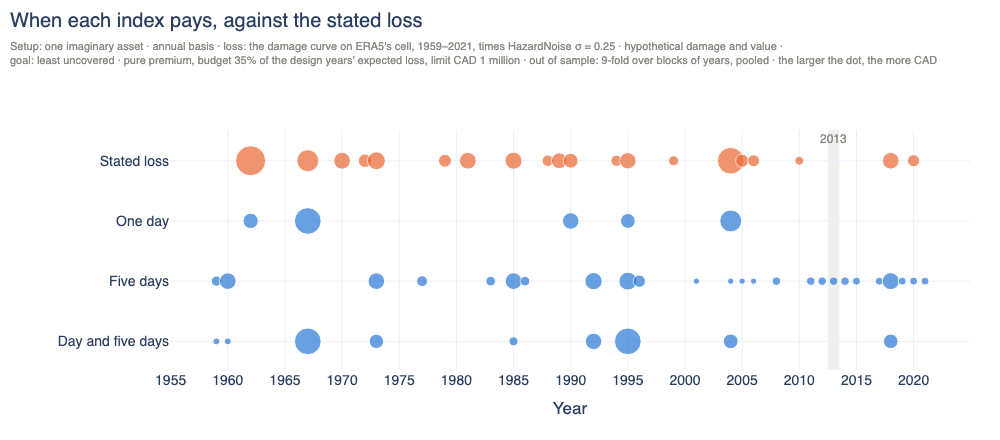

In [6]:
def index_values(cover, block):
    """What a cover reads in a block: one index's values, or one column per index of a contract on several."""
    read = cover.index_definition
    names = read.names if isinstance(read, CompositeIndex) else (read.hazard_name,)
    values = np.column_stack([block.index_components[name].values[:, 0] for name in names])
    return values if isinstance(read, CompositeIndex) else values[:, 0]


# Each year's payout from each index, paid by the design made without that year's block.
held = {name: np.concatenate([chosen.cover.payout_values(index_values(chosen.cover, test))
                              for chosen, (_, test) in zip(fold_designs, folds)])
        for name, fold_designs in designs.items()}
period = np.concatenate([test.period for _, test in folds])
lines = {"Stated loss": record.loss[:, 0], **held}
scale = max(values.max() for values in lines.values())

fig = go.Figure()
for name, values in lines.items():
    what = "loss" if name == "Stated loss" else "pays"
    fig.add_trace(go.Scatter(x=period[values > 0], y=[name] * int((values > 0).sum()), mode="markers", name=name,
                             marker=dict(color=ORANGE if what == "loss" else BLUE, size=5 + 25 * np.sqrt(values[values > 0] / scale),
                                         line=dict(width=1, color="white")),
                             customdata=values[values > 0], hovertemplate=f"{name}<br>%{{x}}: {what} CAD %{{customdata:,.0f}}<extra></extra>"))
fig.add_vrect(x0=2012.5, x1=2013.5, fillcolor=LIGHT, line_width=0, layer="below",
              annotation_text="2013", annotation_position="top", annotation_font=dict(color=MUTED, size=12))
SETUP = (f"Setup: one imaginary asset · annual basis · loss: the damage curve on ERA5's cell, {period.min()}–{period.max()}, times "
         f"HazardNoise σ = {SIGMA} · hypothetical damage and value ·<br>goal: least uncovered · pure premium, budget 35% of the "
         f"design years' expected loss, limit CAD 1 million · out of sample: {K}-fold over blocks of years, pooled")
layout(fig, "When each index pays, against the stated loss", SETUP + " · the larger the dot, the more CAD", height=440, top=130,
       yaxis=dict(categoryorder="array", categoryarray=list(lines)[::-1]), xaxis=dict(title="Year", dtick=5), showlegend=False,
       left=170)
fig.show()

On these years the cover on five days pays in many years without a loss, and
reaches less of the loss for the same premium: the loss follows the wettest day,
and on this cell a year with a very wet day is often not one with a very wet week.
The contract on both lands between the two.

## 3. How sure can we be?

Two things could have come out otherwise: the years, and the factor.
`bootstrap_intervals` redraws the 63 years, holds the designs fixed and recomputes
each number; the blue bars hold the middle 90%. The grey dots redraw the factor
instead, 50 times, each designed again.

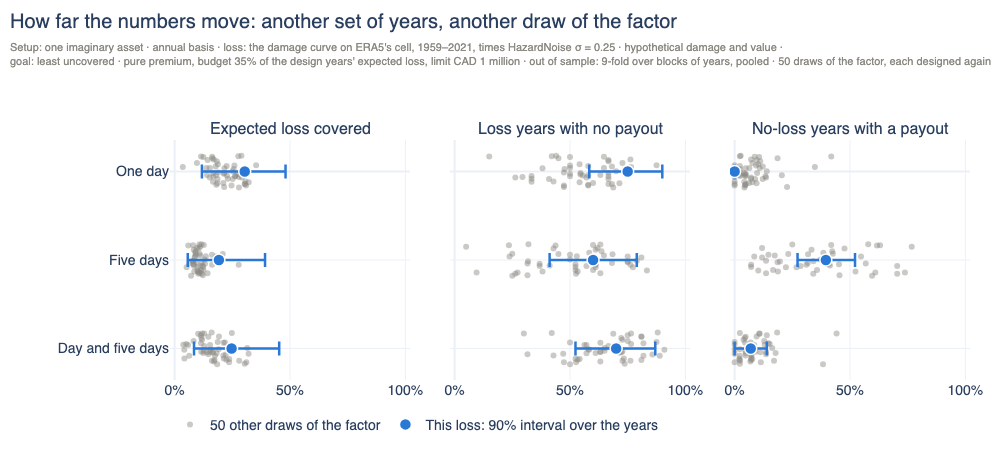

Blue: 2,000 redraws of the years, on the rows of section 2. Grey: 50 draws of the factor (seeds 1000 to 1049 instead of 42), each giving one compare_pooled row per index, with section 2's setup.


In [7]:
intervals = bootstrap_intervals(list(designs.values()), folds, rng=np.random.default_rng(7), n_bootstrap=200 if CI else 2_000,
                                options=OPTIONS).to_pandas()
DRAWS = 10 if CI else 50
redrawn = pd.concat([compare_pooled(list(other.values()), other_folds, options=OPTIONS).to_pandas()
                     for other_folds, other in (designed(stated_loss(seed)) for seed in range(1_000, 1_000 + DRAWS))])

SHOWN = {"coverage_ratio": "Expected loss covered", "false_negative_rate_l0": "Loss years with no payout",
         "false_positive_rate_l0": "No-loss years with a payout"}
names = list(TEMPLATES)
jitter = np.random.default_rng(0).uniform(-0.18, 0.18, DRAWS)
fig = make_subplots(rows=1, cols=len(SHOWN), subplot_titles=list(SHOWN.values()), horizontal_spacing=0.05, shared_yaxes=True)
for number, column in enumerate(SHOWN, start=1):
    for place, name in enumerate(names):
        values = redrawn.loc[redrawn["cover_label"] == name, column].to_numpy()
        fig.add_trace(go.Scatter(x=values, y=place + jitter, mode="markers", name=f"{DRAWS} other draws of the factor",
                                 marker=dict(color=MUTED, size=6, opacity=0.45), showlegend=number == 1 and place == 0,
                                 legendgroup="redrawn", hovertemplate=f"{name}, another draw: %{{x:.0%}}<extra></extra>"),
                      row=1, col=number)
    bars = intervals[intervals["column"] == column].set_index("cover_label").loc[names]
    fig.add_trace(go.Scatter(x=bars["value"], y=np.arange(len(names)), mode="markers", name="This loss: 90% interval over the years",
                             marker=dict(color=BLUE, size=12, line=dict(width=1.5, color="white")), showlegend=number == 1,
                             legendgroup="bootstrap",
                             error_x=dict(type="data", symmetric=False, array=bars["ci_high"] - bars["value"],
                                          arrayminus=bars["value"] - bars["ci_low"], color=BLUE, thickness=2.5, width=7),
                             customdata=np.column_stack([bars["ci_low"], bars["ci_high"]]), text=names,
                             hovertemplate="%{text}: %{x:.0%} (90% interval %{customdata[0]:.0%} to %{customdata[1]:.0%})<extra></extra>"),
                  row=1, col=number)
    fig.update_xaxes(tickformat=".0%", range=[-0.02, 1.02], row=1, col=number)
fig.update_yaxes(tickvals=list(range(len(names))), ticktext=names, autorange="reversed")
layout(fig, "How far the numbers move: another set of years, another draw of the factor",
       SETUP + f" · {DRAWS} draws of the factor, each designed again", height=470, top=140, bottom=90, left=170,
       legend=dict(orientation="h", yanchor="top", y=-0.12, x=0))
fig.show()
print(f"Blue: {intervals['n_bootstrap'].iloc[0]:,} redraws of the years, on the rows of section 2. Grey: {DRAWS} draws of "
      f"the factor (seeds 1000 to {999 + DRAWS} instead of 42), each giving one compare_pooled row per index, with section 2's setup.")

Read both charts as measurements of one setup: this brewery, this loss, these 63
years. The spreads are wide, so a few points between rows say little, and two
intervals are not a test of a difference.

> 💡 **Key idea: test an index on its years.** A curve can say how often an index
> pays; whether it pays in your loss years takes years with both the index and the
> loss. Here the loss was stated; with your own, `OutcomeSample.from_table` takes
> the same steps.

## Where next

- ERA5's free grid is coarse. A station's record would put an index at the street,
  and crc-sdk reads several station networks.
- The module's [guide](https://github.com/marc272/crc-sdk/blob/parametric/docs/parametric.md) covers contracts on several indices.

*An illustration of a method, not insurance advice or a price.*

*Data: ERA5 (Copernicus Climate Change Service, CC BY 4.0), through WeatherBench2's
public 1.5° copy; CRC Open by Riskthinking.AI (CC BY-NC 4.0; SSP5-8.5 only, no
historical baseline). The 2013 facts are from the City of Toronto's staff report of
10 September 2013, accessed 12 November 2026.*